## Homework 7

Choose a text corpus (IMDB reviews, news, or an external dataset, such as Reddit, Yelp, or similar ones).

Produce: an honest frequency visualization, a topic-model visualization, and an embedding projection.

Write a short note on what each view reveals and one way it could mislead.

Submit as a Streamlit app (topic selector) or .ipynb + .html. 

(Optional): Try to incorporate the following:

Add hierarchical topic visualization from BERTopic.

Compare TF-IDF keyness against raw counts.


**Tasks:**

1. Preprocess + sorted frequency bars; note ONE preprocessing choice that changed the result
2. TF–IDF: the 5 most distinctive terms of 2 different documents
3. Project the TF–IDF vectors to 2-D; label points; one honest caption
4. Cluster the projection three ways and compare
5. `app_topic_starter.py`: run it, feed it your corpus, extend one TODO

In [1]:
import sys; print(sys.executable)


/Users/halaassaf/Desktop/Fall 2026/Data Viz/Class 6/.venv/bin/python


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN

In [3]:

data = pd.read_csv("/Users/halaassaf/Desktop/Fall 2026/Data Viz/Class 6/data.csv")

In [4]:
# Task 1 —> Remove stop words and find the top 3 most frequent words in the tweets
for sw in (None, "english"):
    cv = CountVectorizer(stop_words=sw)
    c = cv.fit_transform(data["OriginalTweet"])
    f = pd.Series(c.sum(axis=0).A1, index=cv.get_feature_names_out())
    print(f"stop_words={sw}: top ->", list(f.sort_values().tail(3).index))

stop_words=None: top -> ['and', 'to', 'the']
stop_words=english: top -> ['19', 'coronavirus', 'https']


In [5]:
# Task 2 -> Find the 5 most distinctive words
tfv = TfidfVectorizer(stop_words="english")
T = tfv.fit_transform(data["OriginalTweet"])
for d in (1, 7):
    row = pd.Series(T[d].toarray()[0], index=tfv.get_feature_names_out())
    print(f"tweet {d+1} distinctive:", list(row.sort_values().tail(5).index))

tweet 2 distinctive: ['gp', 'poss', 'phone', 'numbers', 'neighbours']
tweet 8 distinctive: ['buy', 'didn', 'toiletpapercrisis', 'rebel', 'evxkqlidaz']


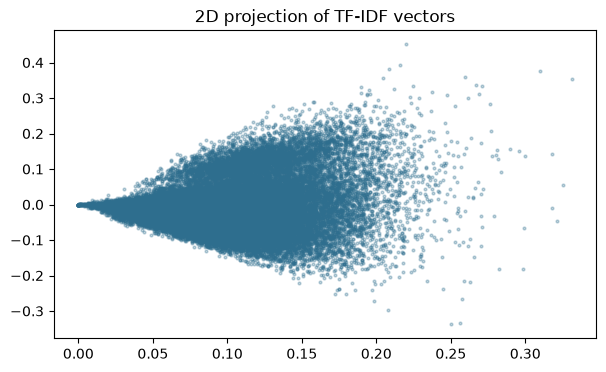

In [6]:
# Task 3 -> Visualize the tweets in 2D 
pcs = TruncatedSVD(n_components=2, random_state=0).fit_transform(T)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pcs[:, 0], pcs[:, 1], s=4, alpha=0.3, color="#2E6E8E")
ax.set_title("2D projection of TF-IDF vectors")
plt.show()


In [7]:
T.size

793416

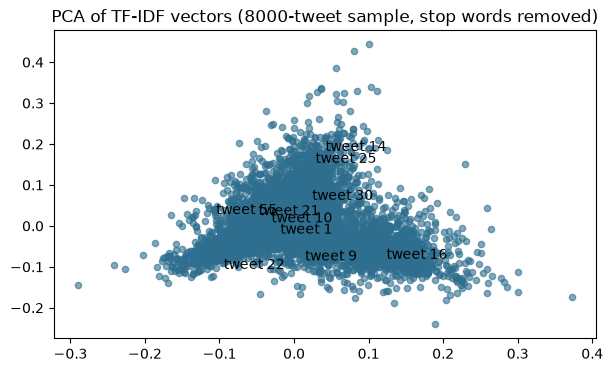

In [8]:
# Sample Run 
import numpy as np

rng = np.random.default_rng(0)
idx = np.sort(rng.choice(T.shape[0], size=8000, replace=False))

pcs = PCA(2).fit_transform(T[idx].toarray())
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pcs[:, 0], pcs[:, 1], s=20, alpha=0.6, color="#2E6E8E")
for i in range(10):
    ax.annotate(f"tweet {idx[i]+1}", pcs[i], xytext=(8, 5), textcoords="offset points")
ax.set_title("PCA of TF-IDF vectors (8000-tweet sample, stop words removed)")
plt.show()


### 2D Projection

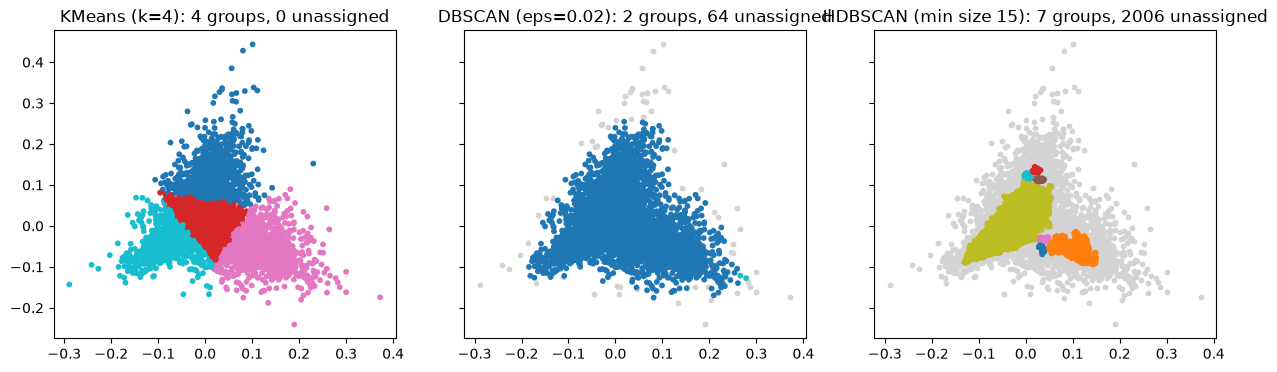

DBSCAN eps=0.01: 7 groups, 253 unassigned
DBSCAN eps=0.02: 2 groups, 64 unassigned
DBSCAN eps=0.03: 2 groups, 16 unassigned


In [9]:
# Task 4 -> Cluster the 2-D projection three ways

Y = pcs                                         
docs = data["OriginalTweet"].iloc[idx].tolist()  

km = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(Y)
db = DBSCAN(eps=0.02, min_samples=5).fit_predict(Y)
hdb = HDBSCAN(min_cluster_size=15, copy=True).fit_predict(Y)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, [("KMeans (k=4)", km), ("DBSCAN (eps=0.02)", db), ("HDBSCAN (min size 15)", hdb)]):
    noise = labels == -1
    ax.scatter(Y[noise, 0], Y[noise, 1], s=10, color="lightgrey")
    ax.scatter(Y[~noise, 0], Y[~noise, 1], s=10, c=labels[~noise], cmap="tab10")
    ax.set_title(f"{name}: {len(set(labels) - {-1})} groups, {noise.sum()} unassigned")
plt.show()

# Task 4b -> DBSCAN at more than one eps
for eps in (0.01, 0.02, 0.03):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(Y)
    print(f"DBSCAN eps={eps}: {len(set(labels) - {-1})} groups, {(labels == -1).sum()} unassigned")


### BERT

In [10]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer

# 2,000 random tweets from the CSV loaded above
docs = data["OriginalTweet"].dropna().sample(2000, random_state=42).tolist()

embedding_model = SentenceTransformer("all-MiniLM-L6-v2", device="mps")  # Mac GPU
topic_model = BERTopic(embedding_model=embedding_model, min_topic_size=5)
topics, probs = topic_model.fit_transform(docs)

topic_model.get_topic_info()

/Users/halaassaf/Desktop/Fall 2026/Data Viz/Class 6/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1016 08:14:02.103000 27956 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8332.79it/s]


,Topic,Count,Name,Representation,Representative_Docs
0,-1,668,-1_the_to_and_in,"[the, to, and, in, co, https, of, for, is, cor...",[This also needs to be said: going to the groc...
1,0,163,0_sanitizer_hand_mask_masks,"[sanitizer, hand, mask, masks, gloves, coronav...",[20 seconds Soap and water Or hand sanitizer W...
2,1,145,1_prices_are_price_the,"[prices, are, price, the, in, to, of, is, for,...",[Some retailers are hiking prices &amp; blatan...
3,2,132,2_grocery_store_coronavirus_supermarket,"[grocery, store, coronavirus, supermarket, co,...",[@nolansclontarf Will you provide a grocery de...
4,3,109,3_consumer_covid_19_https,"[consumer, covid, 19, https, co, the, business...",[Key insights: COVID-19 continues to impact co...
5,4,85,4_toiletpaper_paper_toilet_coronavirus,"[toiletpaper, paper, toilet, coronavirus, toil...",[Me when I find a pack of #toiletpaper in the ...
6,5,82,5_workers_grocery_employees_thank,"[workers, grocery, employees, thank, store, ke...","[In the face of COVID-19, we want to thank the..."
7,6,66,6_panic_buying_food_buy,"[panic, buying, food, buy, people, of, the, an...",[Hi everyone. If you are panic buying and endi...
8,7,33,7_online_shopping_covid_ecommerce,"[online, shopping, covid, ecommerce, 19, comme...",[Shopping online: keeping the economy and busi...
9,8,31,8_food_banks_demand_help,"[food, banks, demand, help, as, donations, sup...",[Food banks are seeing increased demand due to...


In [11]:
topic_model.visualize_topics()

In [12]:
topic_model.visualize_barchart()

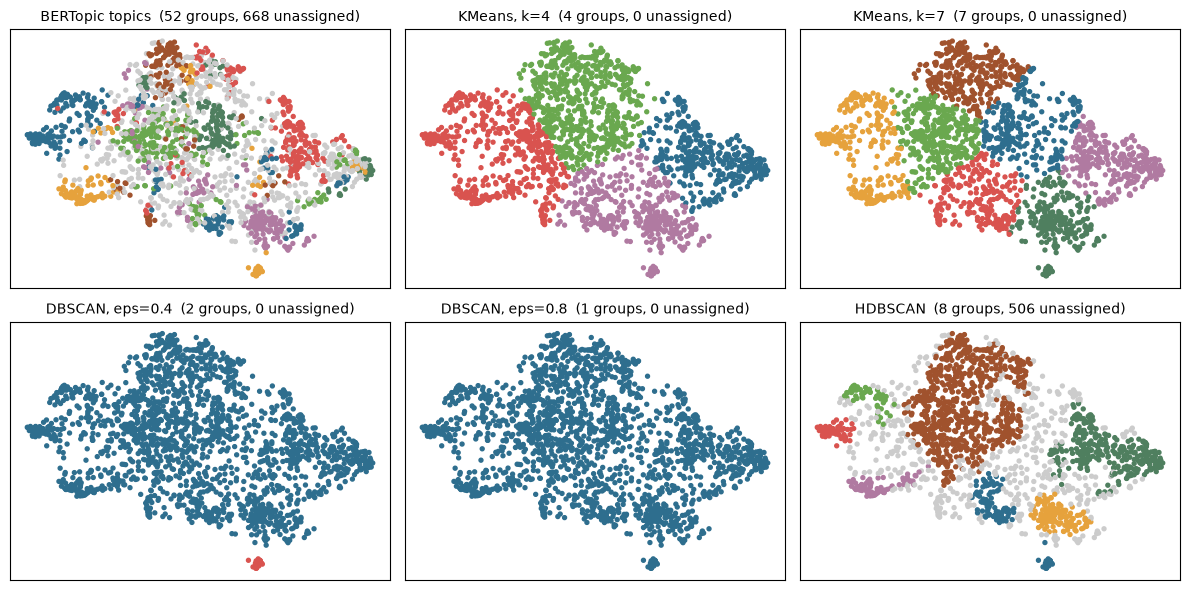

In [14]:
import umap
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN

# Embed the same 2,000 tweets BERTopic used, then project to 2-D
Xs = embedding_model.encode(docs, show_progress_bar=False)
Y = umap.UMAP(n_components=2, random_state=0).fit_transform(Xs)

runs = [
    ("BERTopic topics", np.array(topics)),
    ("KMeans, k=4",     KMeans(4, n_init=10, random_state=0).fit_predict(Y)),
    ("KMeans, k=7",     KMeans(7, n_init=10, random_state=0).fit_predict(Y)),
    ("DBSCAN, eps=0.4", DBSCAN(eps=0.4, min_samples=8).fit_predict(Y)),
    ("DBSCAN, eps=0.8", DBSCAN(eps=0.8, min_samples=8).fit_predict(Y)),
    ("HDBSCAN",         HDBSCAN(min_cluster_size=20).fit_predict(Y)),
]

palette = np.array(["#2E6E8E", "#d9534f", "#6aa84f", "#b07aa1", "#e6a23c",
                    "#4f7f5f", "#a0522d"])
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, (name, lab) in zip(axes.ravel(), runs):
    colours = ["#cccccc" if v == -1 else palette[v % len(palette)] for v in lab]
    found = len(set(lab) - {-1})
    noise = int((np.asarray(lab) == -1).sum())
    ax.scatter(Y[:, 0], Y[:, 1], c=colours, s=8)
    ax.set_title(f"{name}  ({found} groups, {noise} unassigned)", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
